In [1]:
# To help with reading and manipulation of data
import numpy as np
from numpy import array
import pandas as pd

# To help with data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# To split the data
from sklearn.model_selection import train_test_split

# To impute missing values
from sklearn.impute import SimpleImputer

# To do one-hot encoding
from sklearn.preprocessing import OneHotEncoder

# To build a decision tree model
from sklearn.tree import DecisionTreeClassifier

# To get different performance metrics
import sklearn.metrics as metrics
from sklearn.metrics import (
    classification_report, 
    confusion_matrix,
    recall_score,
    accuracy_score,
    precision_score,
    f1_score,
)


# To undersample and oversample the data
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

# To suppress warnings
import warnings
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv(r"C:\Users\New\Desktop\Jupyter Notebook\ML\Over_Under_Sampling_Model_Tuning\Loanclients.csv")

In [3]:
data = df.copy()

### Data Overview

In [4]:
data.head()

,Month,credit_amount,credit_term,Age,sex,education,product_type,having_children_flg,region,income,family_status,phone_operator,is_client,target
0,10,7000,6,25,0,Secondary special education,1,0,0,21000.0,1,0,0,0
1,10,19000,3,54,0,Secondary special education,3,1,1,17000.0,1,3,0,0
2,1,29000,2,36,0,Secondary special education,1,0,2,31000.0,1,2,0,0
3,11,10000,6,46,0,Secondary special education,0,1,1,31000.0,1,3,0,0
4,4,14500,4,39,0,Higher education,1,0,1,26000.0,1,0,0,0


In [5]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Month                1000 non-null   int64  
 1   credit_amount        1000 non-null   int64  
 2   credit_term          1000 non-null   int64  
 3   Age                  1000 non-null   int64  
 4   sex                  1000 non-null   int64  
 5   education            1000 non-null   str    
 6   product_type         1000 non-null   int64  
 7   having_children_flg  1000 non-null   int64  
 8   region               1000 non-null   int64  
 9   income               967 non-null    float64
 10  family_status        1000 non-null   int64  
 11  phone_operator       1000 non-null   int64  
 12  is_client            1000 non-null   int64  
 13  target               1000 non-null   int64  
dtypes: float64(1), int64(12), str(1)
memory usage: 131.5 KB


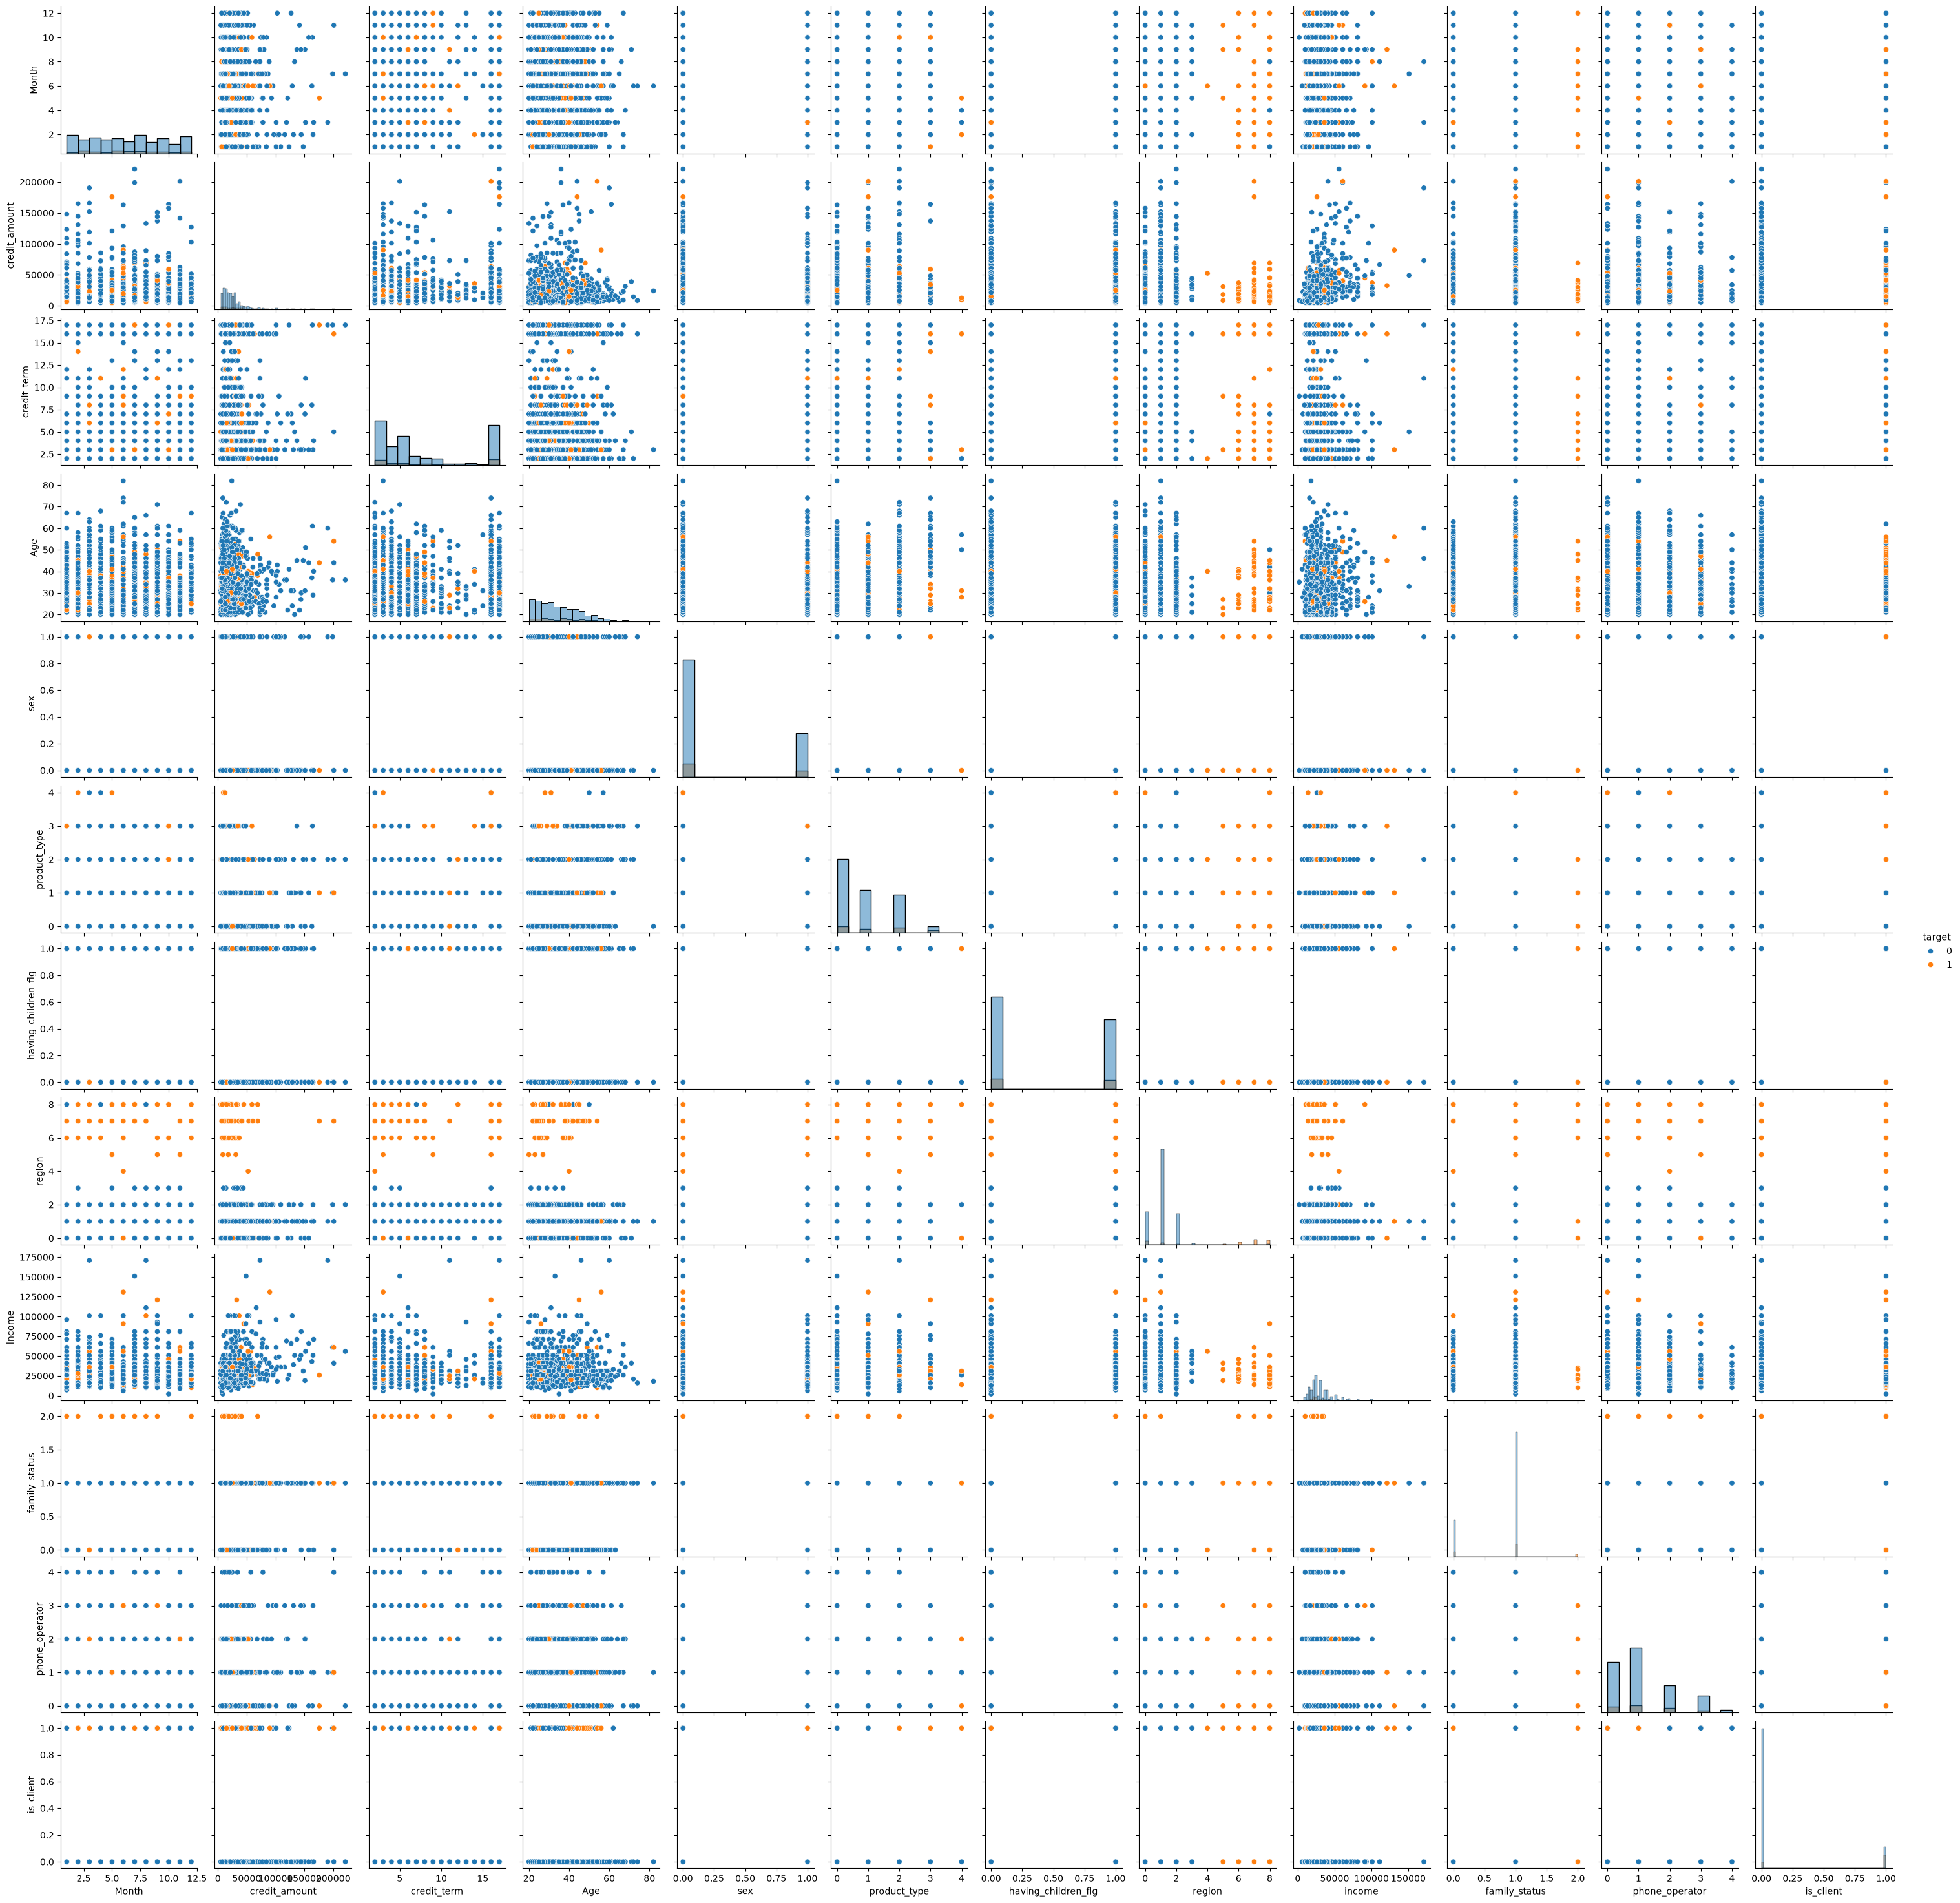

In [6]:
sns.pairplot(data, hue = 'target' , diag_kind='hist')

In [7]:
# checking missing values in the data
data.isna().sum()

Month                   0
credit_amount           0
credit_term             0
Age                     0
sex                     0
education               0
product_type            0
having_children_flg     0
region                  0
income                 33
family_status           0
phone_operator          0
is_client               0
target                  0
dtype: int64

There are missing data in the income column

In [8]:
# categorical variables to category type
data["phone_operator"] = data["phone_operator"].astype("category")
data["product_type"] = data["product_type"].astype("category")
data["education"] = data["education"].astype("category")

In [11]:
# checking the distribution of the target variable
data["target"].value_counts(1)

target
0    0.893
1    0.107
Name: proportion, dtype: float64

### Splitting the data into X and y

In [12]:
# separating the independent and dependent variables
X = data.drop(["target"], axis=1)
y = data["target"]

# creating dummy variables
X = pd.get_dummies(X, drop_first=True)

In [13]:
# Splitting data into training, validation and test set:

# first we split data into 2 parts, say temporary and test
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.5, random_state=0, stratify=y
)

# then we split the temporary set into train and validation
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.4, random_state=0, stratify=y_temp
)

print(X_train.shape, X_val.shape, X_test.shape)

(500, 23) (300, 23) (200, 23)


In [14]:
# Checking class balance for whole data, train set, validation set, and test set

print("Target value ratio in y")
print(y.value_counts(1))
print("*" * 80)
print("Target value ratio in y_train")
print(y_train.value_counts(1))
print("*" * 80)
print("Target value ratio in y_val")
print(y_val.value_counts(1))
print("*" * 80)
print("Target value ratio in y_test")
print(y_test.value_counts(1))
print("*" * 80)

Target value ratio in y
target
0    0.893
1    0.107
Name: proportion, dtype: float64
********************************************************************************
Target value ratio in y_train
target
0    0.892
1    0.108
Name: proportion, dtype: float64
********************************************************************************
Target value ratio in y_val
target
0    0.893333
1    0.106667
Name: proportion, dtype: float64
********************************************************************************
Target value ratio in y_test
target
0    0.895
1    0.105
Name: proportion, dtype: float64
********************************************************************************


## Training a decision tree and checking it's performance

In [15]:
dtree = DecisionTreeClassifier(random_state=1, max_depth=4)

# training the decision tree model with oversampled training set
dtree.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",4
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",1
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at t

In [16]:
print(pd.DataFrame(dtree.feature_importances_, columns = ["imp"], index = X_train.columns))

                                               imp
Month                                     0.000000
credit_amount                             0.000000
credit_term                               0.018772
Age                                       0.000000
sex                                       0.000000
having_children_flg                       0.000000
region                                    0.656550
income                                    0.043484
family_status                             0.182609
is_client                                 0.078218
education_Incomplete higher education     0.000000
education_Incomplete secondary education  0.000000
education_PhD degree                      0.000000
education_Secondary education             0.000000
education_Secondary special education     0.000000
product_type_1                            0.000000
product_type_2                            0.000000
product_type_3                            0.001595
product_type_4                 

In [17]:
# Predicting the target for train and validation set
pred_train = dtree.predict(X_train)
pred_val = dtree.predict(X_val)

In [18]:
# Checking recall score on oversampled train and validation set
print(recall_score(y_train, pred_train))
print(recall_score(y_val, pred_val))

0.8333333333333334
0.5


In [19]:
# Checking accuracy score on oversampled train and validation set
print(accuracy_score(y_train, pred_train))
print(accuracy_score(y_val, pred_val))

0.982
0.9466666666666667


- Accuracy of the model is good but the metric of interest in Recall here.
- The model's recall score is poor for both train and validation sets.

- Let's try oversampling and undersampling techniques to see if recall improves.

### Oversampling and Undersampling the train data

#### Oversampling train data using SMOTE

In [22]:
# Count missing values in each column
X_train.isnull().sum()

Month                                        0
credit_amount                                0
credit_term                                  0
Age                                          0
sex                                          0
having_children_flg                          0
region                                       0
income                                      19
family_status                                0
is_client                                    0
education_Incomplete higher education        0
education_Incomplete secondary education     0
education_PhD degree                         0
education_Secondary education                0
education_Secondary special education        0
product_type_1                               0
product_type_2                               0
product_type_3                               0
product_type_4                               0
phone_operator_1                             0
phone_operator_2                             0
phone_operato

In [23]:
X_train.isnull().sum()[
    X_train.isnull().sum() > 0
]

income    19
dtype: int64

In [29]:


# Create imputer
imputer = SimpleImputer(strategy='median')

# Fit on training data and transform
X_train_imputed = imputer.fit_transform(X_train)

# Transform test data using the same imputer
X_test_imputed = imputer.transform(X_test)

In [30]:


sm = SMOTE(
    sampling_strategy=0.4,
    k_neighbors=5,
    random_state=1
)

X_train_over, y_train_over = sm.fit_resample(
    X_train_imputed,
    y_train
)

In [31]:
# Fit SMOTE on train data(Synthetic Minority Oversampling Technique)
sm = SMOTE(sampling_strategy=0.4, k_neighbors=5, random_state=1)
X_train_over, y_train_over = sm.fit_resample(X_train_imputed, y_train)

In [32]:
print("Before OverSampling, count of label '1': {}".format(sum(y_train == 1)))
print("Before OverSampling, count of label '0': {} \n".format(sum(y_train == 0)))

print("After OverSampling, count of label '1': {}".format(sum(y_train_over == 1)))
print("After OverSampling, count of label '0': {} \n".format(sum(y_train_over == 0)))

print("After OverSampling, the shape of train_X: {}".format(X_train_over.shape))
print("After OverSampling, the shape of train_y: {} \n".format(y_train_over.shape))

Before OverSampling, count of label '1': 54
Before OverSampling, count of label '0': 446 

After OverSampling, count of label '1': 178
After OverSampling, count of label '0': 446 

After OverSampling, the shape of train_X: (624, 23)
After OverSampling, the shape of train_y: (624,) 



#### Training a decision tree classifier using the oversampled data

In [33]:
dtree1 = DecisionTreeClassifier(random_state=1, max_depth=4)

# training the decision tree model with oversampled training set
dtree1.fit(X_train_over, y_train_over)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",4
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",1
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at t

In [34]:
# Predicting the target for train and validation set
pred_train = dtree1.predict(X_train_over)
pred_val = dtree1.predict(X_val)

In [35]:
# Checking recall score on oversampled train and validation set
print(recall_score(y_train_over, pred_train))
print(recall_score(y_val, pred_val))

0.9550561797752809
0.8125


In [36]:
# Checking accuracy score on oversampled train and validation set
print(accuracy_score(y_train_over, pred_train))
print(accuracy_score(y_val, pred_val))

0.9727564102564102
0.9666666666666667


#### After checking the performance, let's look at the confusion matrices of the train and validation data

Text(58.33333333333333, 0.5, 'Actual Values')

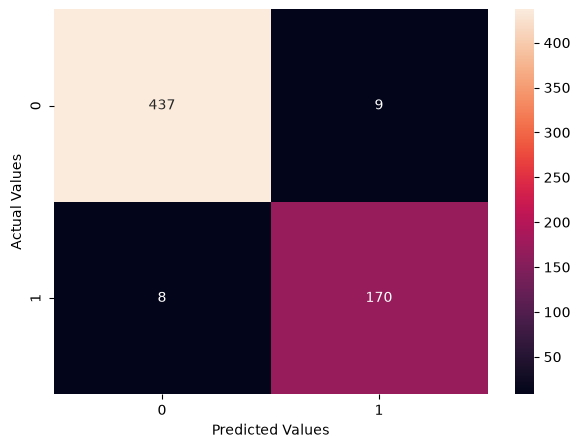

In [37]:
# Confusion matrix for oversampled train data
cm = confusion_matrix(y_train_over, pred_train)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="g")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")


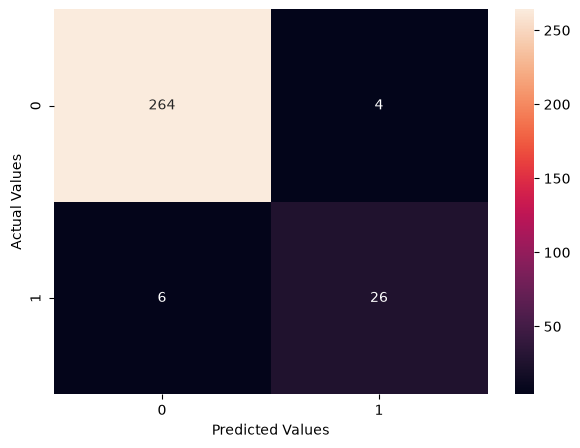

In [38]:
# Confusion matrix for validation data
cm = confusion_matrix(y_val, pred_val)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="g")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.show()

* We can see that the model with oversampled data has improved the train recall from 57% to 92% and 50% to 84% on the validation data
* There is a little overfitting in the results which can be handled separately by using regularization techniques.

## Undersampling train data using Random Undersampler

In [39]:
# fit random under sampler on the train data
rus = RandomUnderSampler(random_state=1, sampling_strategy = 1)
X_train_un, y_train_un = rus.fit_resample(X_train, y_train)

In [40]:
print("Before Under Sampling, count of label '1': {}".format(sum(y_train == 1)))
print("Before Under Sampling, count of label '0': {} \n".format(sum(y_train == 0)))

print("After Under Sampling, count of label '1': {}".format(sum(y_train_un == 1)))
print("After Under Sampling, count of label '0': {} \n".format(sum(y_train_un == 0)))

print("After Under Sampling, the shape of train_X: {}".format(X_train_un.shape))
print("After Under Sampling, the shape of train_y: {} \n".format(y_train_un.shape))

Before Under Sampling, count of label '1': 54
Before Under Sampling, count of label '0': 446 

After Under Sampling, count of label '1': 54
After Under Sampling, count of label '0': 54 

After Under Sampling, the shape of train_X: (108, 23)
After Under Sampling, the shape of train_y: (108,) 

